In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import ollama
import json

In [3]:
df = pd.read_csv("agri01.csv")
df.head()

,crop,state,district,season,year,min_temperature,max_temperature,avg_temperature,rainfall,humidity,...,potassium,irrigation_type,growth_stage,extreme_event,ndvi,area,previous_year_yield,market_price,profit,yield
0,Sugarcane,Uttar Pradesh,Kanpur,Zaid,2022,26.72,39.27,32.72,73.40,42.32,...,43.84,Sprinkler,Sowing,NaN,0.924,4.83,3.62,2709.24,-41538.43,1.95
1,Maize,Tamil Nadu,Coimbatore,Kharif,2017,28.20,38.94,34.02,117.57,40.53,...,128.32,Rain-fed,Flowering,NaN,0.386,9.71,5.55,16493.69,369861.70,2.72
2,Wheat,Punjab,Amritsar,Rabi,2022,14.46,28.22,20.40,89.12,54.95,...,75.04,Drip,Sowing,Flood,0.426,3.91,1.99,24523.69,54185.39,0.85
3,Rice,Tamil Nadu,Madurai,Kharif,2021,17.97,33.07,25.83,191.21,81.22,...,34.42,Drip,Flowering,NaN,0.394,5.63,2.01,23957.64,146010.86,1.32
4,Cotton,Maharashtra,Pune,Rabi,2016,16.63,29.13,21.71,65.82,58.26,...,104.20,Drip,Sowing,NaN,0.382,3.71,5.09,46663.23,393854.06,2.72


In [5]:
def get_dataset_info(df):

    info = {
        "columns": df.columns.tolist(),
        "data_types": df.dtypes.astype(str).to_dict(),
        "shape": df.shape,
        "missing_values": df.isnull().sum().to_dict(),
        "sample_data": df.head(5).to_dict(orient="records")
    }

    return info

In [9]:

def complex_seaborn_query(question, df):

    dataset_info = get_dataset_info(df)

    prompt = f"""
You are an expert Data Analyst and Seaborn visualization query generator.

DATASET INFORMATION:
{json.dumps(dataset_info, default=str)}

USER QUESTION:
{question}

YOUR TASK:
Understand the complete analytical intent of the user's question
and generate ONE valid Seaborn visualization expression.

Use:
- df as the DataFrame.
- sns as the Seaborn library.
- plt as the Matplotlib library.

========================
STRICT RULES
========================

1. Return only one Seaborn expression.
2. Never generate functions or classes.
3. Never generate variable assignments.
4. Never include explanations or comments.
5. Never use Markdown code fences.
6. Use only existing dataset columns.
7. Never invent column names or categorical values.
8. Never include "Query:" or "Answer:".
9. Never use plt.show().
10. Never use Pandas plotting functions.
11. Never generate multiple independent plots.
12. Never use the original df when filtering is required.
13. Use appropriate x, y and hue parameters.
14. Do not generate unnecessary hue parameters.
15. Use plt.title() only when necessary.
16. Return syntactically valid Python code.

========================
ANALYTICAL UNDERSTANDING
========================

Before generating the visualization, internally identify:

1. FILTERS:
   Identify all conditions mentioned in the question.

2. GROUPING:
   Identify which column should be used for grouping.

3. METRIC:
   Identify the numerical column being analyzed.

4. AGGREGATION:
   Determine whether the user wants sum, mean, count,
   median, minimum or maximum.

5. VISUALIZATION:
   Select the most appropriate Seaborn chart.

IMPORTANT:

- Never ignore any filter mentioned in the question.
- Filtering and grouping are different operations.
- Filtering selects records.
- Grouping compares categories.
- Apply all requested filters before visualization.
- Multiple AND conditions must use & with parentheses.
- Multiple OR conditions must use | with parentheses.
- Use isin() when filtering multiple categorical values.
- Never use hue for a category that has already been
  filtered to a single value unless explicitly requested.

========================
AGGREGATION RULES
========================

1. Total, overall, cumulative, or total amount:
   Use estimator="sum".

2. Average or mean:
   Use estimator="mean".

3. Median:
   Use estimator="median".

4. Maximum:
   Use estimator="max".

5. Minimum:
   Use estimator="min".

6. Count or number of records:
   Prefer countplot when counting categories.

7. When aggregation is requested in barplot or lineplot,
   explicitly specify the estimator.

8. Use errorbar=None for aggregated barplot and lineplot
   unless uncertainty visualization is requested.

========================
VISUALIZATION SELECTION
========================

- Numerical distribution: sns.histplot or sns.kdeplot
- Categorical frequency: sns.countplot
- Numerical relationship: sns.scatterplot
- Correlation: sns.heatmap
- Outlier detection: sns.boxplot
- Categorical vs numerical: sns.boxplot or sns.violinplot
- Category-wise numerical aggregation: sns.barplot
- Time-based trend: sns.lineplot
- Multiple category comparison: use hue appropriately.

========================
EXAMPLES
========================

Question: Show age distribution.

Output:
sns.histplot(data=df, x="Age", kde=True)


Question: Show relationship between age and salary.

Output:
sns.scatterplot(data=df, x="Age", y="Salary")


Question: Show count of people in each state.

Output:
sns.countplot(data=df, x="State")


Question: Show correlation between numerical columns.

Output:
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm")


Question: Show outliers in salary.

Output:
sns.boxplot(data=df, y="Salary")


Question: Compare average salary across departments.

Output:
sns.barplot(data=df, x="Department", y="Salary", estimator="mean", errorbar=None)


Question: Year-wise total profit report of Odisha state.

Output:
sns.barplot(data=df[df["state"] == "Odisha"], x="year", y="profit", estimator="sum", errorbar=None)


Question: Show average sales of electronics in 2024.

Output:
sns.barplot(data=df[(df["category"] == "Electronics") & (df["year"] == 2024)], x="category", y="sales", estimator="mean", errorbar=None)


Question: Compare yearly sales of Odisha and Bihar.

Output:
sns.barplot(data=df[df["state"].isin(["Odisha", "Bihar"])], x="year", y="sales", hue="state", estimator="sum", errorbar=None)


Question: Show monthly profit trend for Odisha in 2024.

Output:
sns.lineplot(data=df[(df["state"] == "Odisha") & (df["year"] == 2024)], x="month", y="profit", estimator="sum", errorbar=None)


Question: Compare average profit between different states in 2024.

Output:
sns.barplot(data=df[df["year"] == 2024], x="state", y="profit", estimator="mean", errorbar=None)


Question: Show relationship between age and salary for male employees
working in the IT department.

Output:
sns.scatterplot(data=df[(df["Gender"] == "Male") & (df["Department"] == "IT")], x="Age", y="Salary")


Question: Show sales distribution by region for electronics products.

Output:
sns.boxplot(data=df[df["category"] == "Electronics"], x="region", y="sales")


========================
FINAL VALIDATION
========================

Before returning the expression, internally verify:

1. Are all requested filters applied?
2. Are all column names valid?
3. Is the aggregation correct?
4. Is the chart type appropriate?
5. Is hue being used correctly?
6. Does the expression represent the complete question?
7. Is the Python syntax valid?

If the question requests a specific category or value,
never silently omit that condition.

Return ONLY the final Seaborn expression.
"""

    response = ollama.chat(
        model="llama3.2:3b",
        messages=[
            {
                "role": "system",
                "content": """
You are a strict Seaborn visualization generator.
Generate exactly one valid Seaborn expression.
Understand filters, grouping and aggregation correctly.
Never ignore conditions mentioned by the user.
Never generate functions, classes or variable assignments.
Return only Python code.
"""
            },
            {
                "role": "user",
                "content": prompt
            }
        ],
        options={
            "temperature": 0,
            "num_predict": 200
        }
    )

    query = response["message"]["content"].strip()

    # Remove Markdown code fences
    query = query.replace("```python", "").replace("```", "").strip()

    return query


In [36]:
ques2=complex_seaborn_query('box plot of profit state wise',df)
print(ques2)

sns.boxplot(data=df, x="state", y="profit")


[]

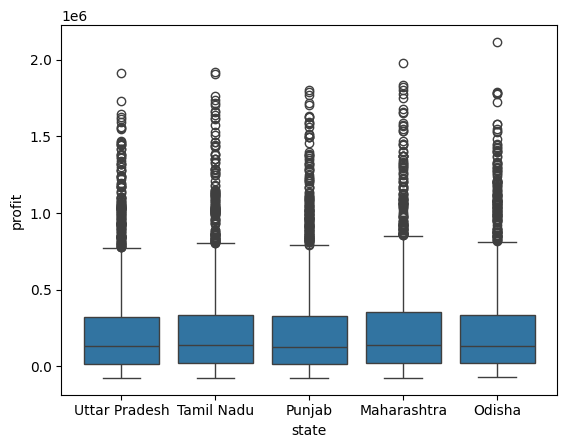

In [37]:
eval(ques2)
plt.plot()